In [1]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Mašinsko učenje/clean_dataset.csv')


In [3]:
print("Dimenzije dataseta:", df.shape)
display(df.head())

df.info()

Dimenzije dataseta: (10127, 20)


,Attrition_Flag_clean,Customer_Age_clean,Gender_clean,Dependent_count_clean,Education_Level_clean,Marital_Status_clean,Income_Category_clean,Card_Category_clean,Months_on_book_clean,Total_Relationship_Count_clean,Months_Inactive_clean,Contacts_Count_clean,Credit_Limit_clean,Total_Revolving_Bal_clean,Avg_Open_To_Buy_clean,Total_Amt_Chng_clean,Total_Trans_Amt_clean,Total_Trans_Ct_clean,Total_Ct_Chng_clean,Avg_Utilization_Ratio_clean
0,Existing Customer,45.0,M,3.0,High School,Married,$60K - $80K,Blue,39.0,4.0,1.0,3.0,4537.0,777.0,3473.0,0.737,1144.0,42.0,1.625,0.061
1,Existing Customer,49.0,F,5.0,Graduate,Single,Less than $40K,Blue,44.0,6.0,1.0,2.0,8256.0,1249.0,3473.0,0.737,1291.0,67.0,3.714,0.105
2,Existing Customer,46.0,M,3.0,Graduate,Married,$80K - $120K,Blue,36.0,4.0,1.0,2.0,3418.0,0.0,3418.0,2.594,1887.0,20.0,2.333,0.000
3,Existing Customer,46.0,F,4.0,High School,Unknown,Less than $40K,Blue,34.0,3.0,4.0,2.0,3313.0,1249.0,796.0,1.405,1171.0,20.0,2.333,0.760
4,Existing Customer,46.0,M,3.0,Uneducated,Married,$60K - $80K,Blue,36.0,5.0,2.0,2.0,4716.0,0.0,4716.0,2.175,3899.0,28.0,2.500,0.000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Attrition_Flag_clean            10127 non-null  object 
 1   Customer_Age_clean              10127 non-null  float64
 2   Gender_clean                    10127 non-null  object 
 3   Dependent_count_clean           10127 non-null  float64
 4   Education_Level_clean           10127 non-null  object 
 5   Marital_Status_clean            10127 non-null  object 
 6   Income_Category_clean           10127 non-null  object 
 7   Card_Category_clean             10127 non-null  object 
 8   Months_on_book_clean            10127 non-null  float64
 9   Total_Relationship_Count_clean  10127 non-null  float64
 10  Months_Inactive_clean           10127 non-null  float64
 11  Contacts_Count_clean            10127 non-null  float64
 12  Credit_Limit_clean              

In [4]:
df.shape

df.describe()


,Customer_Age_clean,Dependent_count_clean,Months_on_book_clean,Total_Relationship_Count_clean,Months_Inactive_clean,Contacts_Count_clean,Credit_Limit_clean,Total_Revolving_Bal_clean,Avg_Open_To_Buy_clean,Total_Amt_Chng_clean,Total_Trans_Amt_clean,Total_Trans_Ct_clean,Total_Ct_Chng_clean,Avg_Utilization_Ratio_clean
count,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,46.253678,2.252395,35.941641,3.858793,2.271749,2.351832,7668.872904,1155.887528,6587.007811,0.755020,4294.708206,65.292387,0.709383,0.245198
std,7.050153,1.171324,7.019558,1.376924,0.902963,1.009995,8145.050193,739.854987,8204.599736,0.196356,2985.454173,20.641201,0.215126,0.249181
min,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,10.000000,0.000000,510.000000,10.000000,0.000000,0.000000
25%,43.000000,2.000000,34.000000,3.000000,2.000000,2.000000,2909.500000,725.000000,1601.500000,0.665000,2530.000000,52.000000,0.618000,0.048000
50%,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4537.000000,1249.000000,3473.000000,0.737000,3899.000000,67.000000,0.700000,0.163000
75%,50.000000,3.000000,38.000000,5.000000,3.000000,3.000000,8302.000000,1637.500000,7254.000000,0.819000,4503.000000,76.000000,0.780000,0.386000
max,68.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,17744.000000,139.000000,3.714000,0.999000


In [5]:
df.isnull().sum()


,0
Attrition_Flag_clean,0
Customer_Age_clean,0
Gender_clean,0
Dependent_count_clean,0
Education_Level_clean,0
Marital_Status_clean,0
Income_Category_clean,0
Card_Category_clean,0
Months_on_book_clean,0
Total_Relationship_Count_clean,0


In [6]:
df.dtypes.value_counts()


,count
float64,14
object,6


In [7]:
df["Attrition_Flag_clean"].value_counts()


,count
Attrition_Flag_clean,
Existing Customer,8483
Attrited Customer,1644


# Podjela podataka i izgradnja modela

In [8]:
TARGET = "Attrition_Flag_clean"

X = df.drop(columns=[TARGET])
y = df[TARGET]


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("\nDistribucija klasa:")
print("Train:\n", y_train.value_counts(normalize=True))
print("Validation:\n", y_val.value_counts(normalize=True))
print("Test:\n", y_test.value_counts(normalize=True))


Train shape: (7088, 19)
Validation shape: (1519, 19)
Test shape: (1520, 19)

Distribucija klasa:
Train:
 Attrition_Flag_clean
Existing Customer    0.837613
Attrited Customer    0.162387
Name: proportion, dtype: float64
Validation:
 Attrition_Flag_clean
Existing Customer    0.838051
Attrited Customer    0.161949
Name: proportion, dtype: float64
Test:
 Attrition_Flag_clean
Existing Customer    0.8375
Attrited Customer    0.1625
Name: proportion, dtype: float64


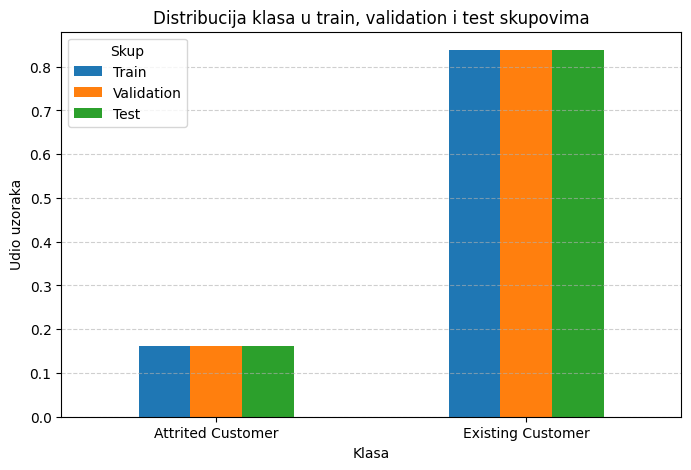

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

dist_df = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True)
})

dist_df = dist_df.sort_index()

# crtanje grafa
ax = dist_df.plot(kind="bar", figsize=(8,5))
plt.title("Distribucija klasa u train, validation i test skupovima")
plt.ylabel("Udio uzoraka")
plt.xlabel("Klasa")
plt.xticks(rotation=0)
plt.legend(title="Skup")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()


In [11]:
import pandas as pd

TARGET = "Attrition_Flag_clean"

X = df.drop(columns=[TARGET])
y = df[TARGET]

X = pd.get_dummies(X, drop_first=True)

print("Nakon enkodiranja X shape:", X.shape)
print("Ima li i dalje stringova?", (X.dtypes == "object").any())


Nakon enkodiranja X shape: (10127, 33)
Ima li i dalje stringova? False


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(" Model istreniran!")


 Model istreniran!


In [13]:
y_val_pred = rf.predict(X_val)


In [14]:
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score

cm = confusion_matrix(y_val, y_val_pred)
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_val, y_val_pred)
sensitivity = tp / (tp + fn)      # recall
specificity = tn / (tn + fp)
kappa = cohen_kappa_score(y_val, y_val_pred)

print("Confusion matrix (VALIDATION):")
print(cm)

print(f"\nAccuracy: {accuracy:.4f}")
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Cohen Kappa: {kappa:.4f}")


Confusion matrix (VALIDATION):
[[ 152   94]
 [  19 1254]]

Accuracy: 0.9256
Sensitivity (Recall): 0.9851
Specificity: 0.6179
Cohen Kappa: 0.6875


In [15]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    cohen_kappa_score
)

cm = confusion_matrix(y_val, y_val_pred)
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_val, y_val_pred)
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
precision = tp / (tp + fp)
kappa = cohen_kappa_score(y_val, y_val_pred)

print("Confusion matrix (VALIDATION):")
print(cm)

print(f"\nAccuracy: {accuracy:.4f}")
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Cohen Kappa: {kappa:.4f}")


Confusion matrix (VALIDATION):
[[ 152   94]
 [  19 1254]]

Accuracy: 0.9256
Sensitivity (Recall): 0.9851
Specificity: 0.6179
Precision: 0.9303
Cohen Kappa: 0.6875


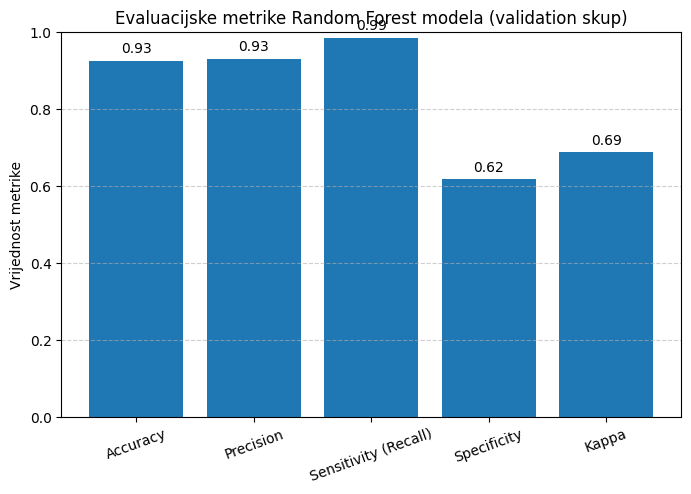

In [16]:
import matplotlib.pyplot as plt

metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Sensitivity (Recall)": sensitivity,
    "Specificity": specificity,
    "Kappa": kappa
}

plt.figure(figsize=(8,5))
plt.bar(metrics.keys(), metrics.values())
plt.ylim(0, 1)
plt.ylabel("Vrijednost metrike")
plt.title("Evaluacijske metrike Random Forest modela (validation skup)")
plt.xticks(rotation=20)

# ispis vrijednosti iznad stubaca
for i, value in enumerate(metrics.values()):
    plt.text(i, value + 0.02, f"{value:.2f}", ha="center")

plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()


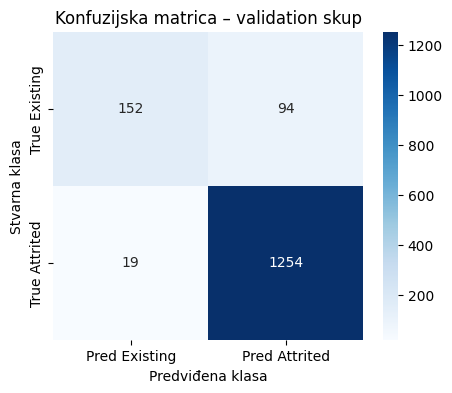

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Existing", "Pred Attrited"],
    yticklabels=["True Existing", "True Attrited"]
)

plt.title("Konfuzijska matrica – validation skup")
plt.xlabel("Predviđena klasa")
plt.ylabel("Stvarna klasa")
plt.show()


In [18]:
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

accs, precs, recs, specs, kappas = [], [], [], [], []

for train_idx, test_idx in cv.split(X, y):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

    rf_cv = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    rf_cv.fit(X_tr, y_tr)
    y_pred = rf_cv.predict(X_te)

    cm = confusion_matrix(y_te, y_pred)
    tn, fp, fn, tp = cm.ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0              # sensitivity
    specificity = tn / (tn + fp) if (tn + fp) else 0
    kappa = cohen_kappa_score(y_te, y_pred)

    accs.append(accuracy)
    precs.append(precision)
    recs.append(recall)
    specs.append(specificity)
    kappas.append(kappa)

print("5-Fold Stratified Cross-Validation (mean ± std)")
print(f"Accuracy:     {np.mean(accs):.4f} ± {np.std(accs):.4f}")
print(f"Precision:    {np.mean(precs):.4f} ± {np.std(precs):.4f}")
print(f"Recall:       {np.mean(recs):.4f} ± {np.std(recs):.4f}")
print(f"Specificity:  {np.mean(specs):.4f} ± {np.std(specs):.4f}")
print(f"Kappa:        {np.mean(kappas):.4f} ± {np.std(kappas):.4f}")


5-Fold Stratified Cross-Validation (mean ± std)
Accuracy:     0.9239 ± 0.0018
Precision:    0.9308 ± 0.0020
Recall:       0.9821 ± 0.0033
Specificity:  0.6235 ± 0.0129
Kappa:        0.6838 ± 0.0071


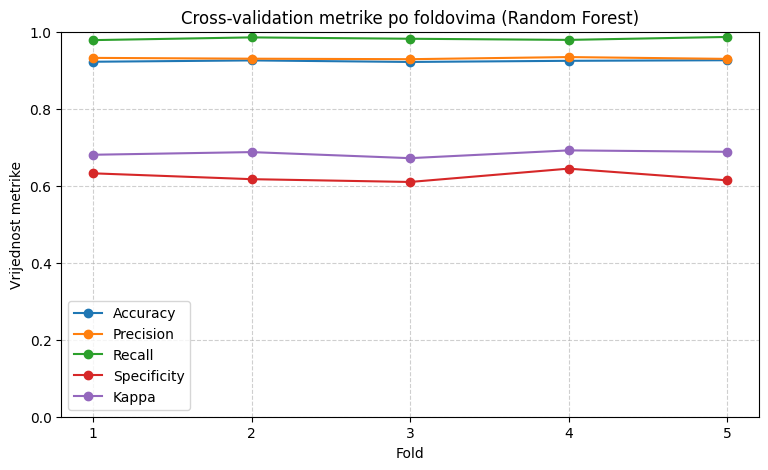

In [19]:
import matplotlib.pyplot as plt

metrics_cv = {
    "Accuracy": accs,
    "Precision": precs,
    "Recall": recs,
    "Specificity": specs,
    "Kappa": kappas
}

plt.figure(figsize=(9,5))
for name, values in metrics_cv.items():
    plt.plot(range(1, len(values)+1), values, marker="o", label=name)

plt.xticks(range(1, 6))
plt.ylim(0, 1)
plt.xlabel("Fold")
plt.ylabel("Vrijednost metrike")
plt.title("Cross-validation metrike po foldovima (Random Forest)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()


# SMOTE

In [20]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, cohen_kappa_score

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Distribucija prije SMOTE:\n", y_train.value_counts())
print("\nDistribucija poslije SMOTE:\n", y_train_sm.value_counts())

rf_smote = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_sm, y_train_sm)


Distribucija prije SMOTE:
 Attrition_Flag_clean
Existing Customer    5937
Attrited Customer    1151
Name: count, dtype: int64

Distribucija poslije SMOTE:
 Attrition_Flag_clean
Attrited Customer    5937
Existing Customer    5937
Name: count, dtype: int64


RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)

In [25]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    cohen_kappa_score
)
y_val_pred_sm = rf_smote.predict(X_val)

cm_sm = confusion_matrix(y_val, y_val_pred_sm)
tn, fp, fn, tp = cm_sm.ravel()

accuracy_sm = accuracy_score(y_val, y_val_pred_sm)

precision_sm = precision_score(
    y_val,
    y_val_pred_sm,
    pos_label="Attrited Customer"
)

recall_sm = tp / (tp + fn) if (tp + fn) else 0
specificity_sm = tn / (tn + fp) if (tn + fp) else 0
kappa_sm = cohen_kappa_score(y_val, y_val_pred_sm)

print("Confusion matrix (SMOTE, VALIDATION):\n", cm_sm)
print(f"Accuracy: {accuracy_sm:.4f}")
print(f"Precision: {precision_sm:.4f}")
print(f"Recall (Sensitivity): {recall_sm:.4f}")
print(f"Specificity: {specificity_sm:.4f}")
print(f"Kappa: {kappa_sm:.4f}")


Confusion matrix (SMOTE, VALIDATION):
 [[ 157   89]
 [  43 1230]]
Accuracy: 0.9131
Precision: 0.7850
Recall (Sensitivity): 0.9662
Specificity: 0.6382
Kappa: 0.6537


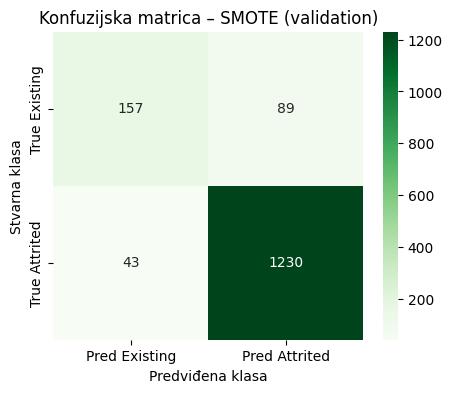

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5,4))
sns.heatmap(
    cm_sm, annot=True, fmt="d", cmap="Greens",
    xticklabels=["Pred Existing", "Pred Attrited"],
    yticklabels=["True Existing", "True Attrited"]
)
plt.title("Konfuzijska matrica – SMOTE (validation)")
plt.xlabel("Predviđena klasa")
plt.ylabel("Stvarna klasa")
plt.show()


In [27]:
import pandas as pd

compare = pd.DataFrame({
    "Bez SMOTE": [accuracy, precision, sensitivity, specificity, kappa],
    "Sa SMOTE":  [accuracy_sm, precision_sm, recall_sm, specificity_sm, kappa_sm]
}, index=["Accuracy", "Precision", "Recall", "Specificity", "Kappa"])

display(compare)


,Bez SMOTE,Sa SMOTE
Accuracy,0.925926,0.913101
Precision,0.929444,0.785000
Recall,0.985075,0.966222
Specificity,0.613982,0.638211
Kappa,0.688078,0.653744


# TUNING PARAMETARA

In [28]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

param_dist = {
    "n_estimators": [200, 300, 500, 800],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
    "bootstrap": [True, False]
}

rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)


In [36]:
from sklearn.metrics import make_scorer, recall_score

recall_scorer = make_scorer(recall_score, pos_label="Attrited Customer")

search = RandomizedSearchCV(
    rf_base,
    param_distributions=param_dist,
    n_iter=25,
    scoring=recall_scorer,
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)


Fitting 5 folds for each of 25 candidates, totalling 125 fits


RandomizedSearchCV(cv=5,
                   estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
                   n_iter=25, n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [None, 5, 10, 15, 20],
                                        'max_features': ['sqrt', 'log2', None],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [200, 300, 500, 800]},
                   random_state=42,
                   scoring=make_scorer(recall_score, response_method='predict', pos_label=Attrited Customer),
                   verbose=1)

In [37]:
print("Najbolji parametri:")
print(search.best_params_)

print("\nNajbolji CV recall:")
print(search.best_score_)


Najbolji parametri:
{'n_estimators': 800, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 15, 'bootstrap': True}

Najbolji CV recall:
0.6907284020327498


In [38]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, cohen_kappa_score

best_rf = search.best_estimator_

y_val_pred_tuned = best_rf.predict(X_val)

cm_tuned = confusion_matrix(y_val, y_val_pred_tuned)
tn, fp, fn, tp = cm_tuned.ravel()

accuracy_tuned = accuracy_score(y_val, y_val_pred_tuned)
precision_tuned = precision_score(
    y_val, y_val_pred_tuned, pos_label="Attrited Customer"
)
recall_tuned = tp / (tp + fn) if (tp + fn) else 0
specificity_tuned = tn / (tn + fp) if (tn + fp) else 0
kappa_tuned = cohen_kappa_score(y_val, y_val_pred_tuned)

print("Confusion matrix (TUNED, VALIDATION):\n", cm_tuned)
print(f"Accuracy: {accuracy_tuned:.4f}")
print(f"Precision: {precision_tuned:.4f}")
print(f"Recall: {recall_tuned:.4f}")
print(f"Specificity: {specificity_tuned:.4f}")
print(f"Kappa: {kappa_tuned:.4f}")


Confusion matrix (TUNED, VALIDATION):
 [[ 172   74]
 [  41 1232]]
Accuracy: 0.9243
Precision: 0.8075
Recall: 0.9678
Specificity: 0.6992
Kappa: 0.7051


In [39]:
import pandas as pd

compare_tuning = pd.DataFrame({
    "Baseline": [accuracy, precision, sensitivity, specificity, kappa],
    "Tuned RF": [accuracy_tuned, precision_tuned, recall_tuned, specificity_tuned, kappa_tuned]
}, index=["Accuracy", "Precision", "Recall", "Specificity", "Kappa"])

display(compare_tuning)


,Baseline,Tuned RF
Accuracy,0.925926,0.924292
Precision,0.929444,0.807512
Recall,0.985075,0.967793
Specificity,0.613982,0.699187
Kappa,0.688078,0.705136


In [40]:
y_test_pred = best_rf.predict(X_test)


In [41]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, cohen_kappa_score

cm_test = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm_test.ravel()

accuracy_test = accuracy_score(y_test, y_test_pred)
precision_test = precision_score(
    y_test,
    y_test_pred,
    pos_label="Attrited Customer"
)
recall_test = tp / (tp + fn) if (tp + fn) else 0
specificity_test = tn / (tn + fp) if (tn + fp) else 0
kappa_test = cohen_kappa_score(y_test, y_test_pred)

print("Confusion matrix (FINAL TEST):\n", cm_test)
print(f"Accuracy: {accuracy_test:.4f}")
print(f"Precision: {precision_test:.4f}")
print(f"Recall (Sensitivity): {recall_test:.4f}")
print(f"Specificity: {specificity_test:.4f}")
print(f"Kappa: {kappa_test:.4f}")


Confusion matrix (FINAL TEST):
 [[ 171   76]
 [  36 1237]]
Accuracy: 0.9263
Precision: 0.8261
Recall (Sensitivity): 0.9717
Specificity: 0.6923
Kappa: 0.7104


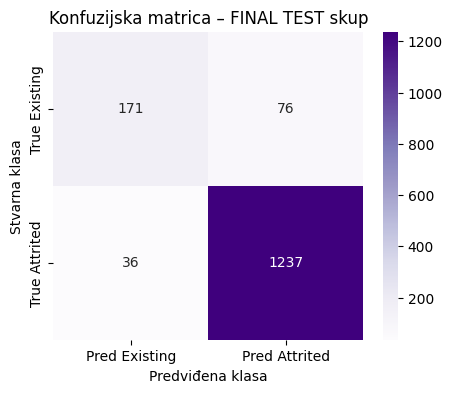

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5,4))
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Pred Existing", "Pred Attrited"],
    yticklabels=["True Existing", "True Attrited"]
)
plt.title("Konfuzijska matrica – FINAL TEST skup")
plt.xlabel("Predviđena klasa")
plt.ylabel("Stvarna klasa")
plt.show()
